# B.Inf.1240: Visualization 

Submitted by: 
Pablo Mancheno - 22467237;
Parisa Vesal - 24774205;
Umadevi V H - 21067231.


# Problem 2: German census data 2022.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression

pd.set_option("display.max_rows", 100)

census = pd.read_csv("data_census.csv", sep=";")
locations = pd.read_csv("municipality-locations.csv", sep=";")

age_order = [
    "<=3", "3-5", "6-14", "15-17", "18-24", "25-29",
    "30-39", "40-49", "50-64", "65-74", ">=75"
]

## 2.1 Import and inspect the data

In [2]:
print("Census shape:", census.shape)
print("Location shape:", locations.shape)
print("\nCensus columns:", census.columns.tolist())
print("Location columns:", locations.columns.tolist())

display(census.head())
display(locations.head())

print("\nAge groups:", census["Age"].unique())
print("Marital-status groups:", census["Marital status"].unique())
print("Gender groups:", census["Gender"].unique())

Census shape: (2328671, 6)
Location shape: (10786, 4)

Census columns: ['Municipality', 'MunicipalityID', 'Age', 'Marital status', 'Gender', 'Count']
Location columns: ['MunicipalityID', 'Municipality', 'lon', 'lat']


,Municipality,MunicipalityID,Age,Marital status,Gender,Count
0,Enzen,72325008032,40-49,Overall,Overall,3
1,Bernitt,130725252013,Overall,Married,Male,319
2,Leidenborn,72325001259,30-39,Divorced,Female,0
3,Schwielowsee,120690590590,50-64,Overall,Male,1450
4,Heßheim,73385006012,40-49,Overall,Female,175


,MunicipalityID,Municipality,lon,lat
0,10010000000,Flensburg,9.437510,54.782520
1,10020000000,Kiel,10.137270,54.321775
2,10030000000,Lübeck,10.683932,53.866269
3,10040000000,Neumünster,9.988422,54.069895
4,10510011011,Brunsbüttel,9.137350,53.896932



Age groups: <ArrowStringArray>
[  '40-49', 'Overall',   '30-39',   '50-64',   '15-17',   '18-24',   '25-29',
   '65-74',    '>=75',    '6-14',     '3-5',     '<=3']
Length: 12, dtype: str
Marital-status groups: <ArrowStringArray>
['Overall', 'Married', 'Divorced', 'Widowed', 'Single', 'No info']
Length: 6, dtype: str
Gender groups: <ArrowStringArray>
['Overall', 'Male', 'Female']
Length: 3, dtype: str


The census table contains 2,328,671 rows and 6 columns. There are 11 actual age brackets plus Overall, five actual marital-status categories plus Overall, and two genders plus Overall. The location table contains one longitude/latitude pair for each real municipality. The census also contains a special national Municipality = Overall row with MunicipalityID = 0; it is excluded whenever individual municipalities are analyzed.

## 2.2 Distribution of municipality sizes
For municipality size, all non-municipality dimensions are fixed to Overall. This gives one population count per municipality without reconstructing totals from masked detailed rows.

In [3]:
municipality_size = census[
    (census["MunicipalityID"] != 0) &
    (census["Age"] == "Overall") &
    (census["Marital status"] == "Overall") &
    (census["Gender"] == "Overall")
][["MunicipalityID", "Municipality", "Count"]].rename(columns={"Count": "Population"})

print("Number of municipalities:", len(municipality_size))
print("Sum of municipality populations:", f'{municipality_size["Population"].sum():,}')
print("Median municipality population:", f'{municipality_size["Population"].median():,.0f}')
print("Largest municipality:")
display(municipality_size.nlargest(1, "Population"))

Number of municipalities: 10786
Sum of municipality populations: 82,711,282
Median municipality population: 1,797
Largest municipality:


,MunicipalityID,Municipality,Population
2223183,110000000000,"Berlin, Stadt",3596999


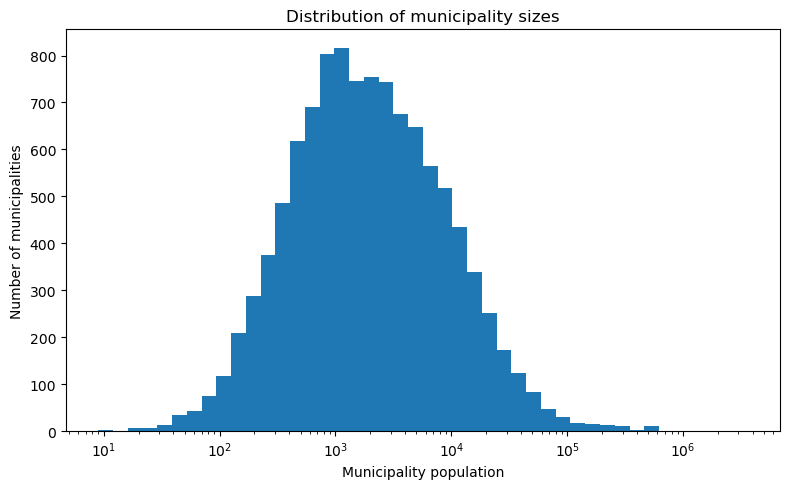

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
bins = np.logspace(
    np.log10(municipality_size["Population"].min()),
    np.log10(municipality_size["Population"].max()),
    45
)
ax.hist(municipality_size["Population"], bins=bins)
ax.set_xscale("log")
ax.set_xlabel("Municipality population")
ax.set_ylabel("Number of municipalities")
ax.set_title("Distribution of municipality sizes")
plt.tight_layout()
plt.show()

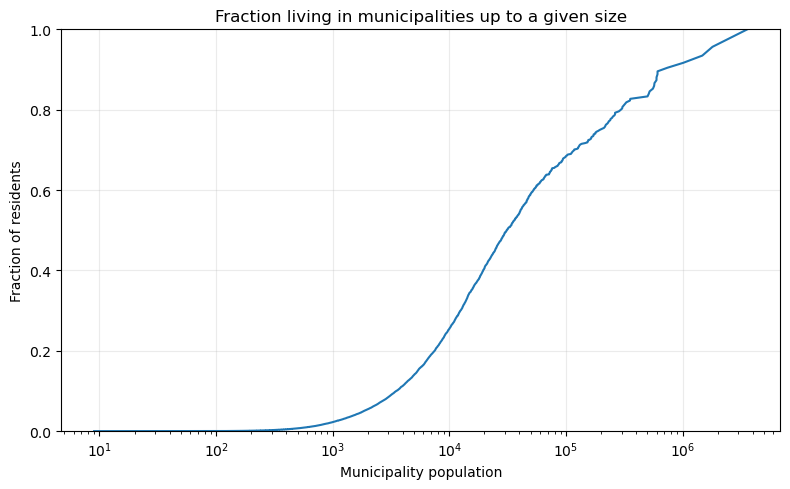

,Municipality size up to,Fraction of residents
0,1000,2.2%
1,2000,5.4%
2,5000,14.0%
3,10000,25.4%
4,20000,40.5%
5,50000,59.1%
6,100000,68.4%
7,500000,82.7%
8,1000000,90.4%


In [5]:
size_sorted = municipality_size.sort_values("Population").copy()
size_sorted["CumulativePopulationFraction"] = (
    size_sorted["Population"].cumsum() / size_sorted["Population"].sum()
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(size_sorted["Population"], size_sorted["CumulativePopulationFraction"])
ax.set_xscale("log")
ax.set_ylim(0, 1)
ax.set_xlabel("Municipality population")
ax.set_ylabel("Fraction of residents")
ax.set_title("Fraction living in municipalities up to a given size")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

thresholds = [1_000, 2_000, 5_000, 10_000, 20_000, 50_000, 100_000, 500_000, 1_000_000]
threshold_table = pd.DataFrame({
    "Municipality size up to": thresholds,
    "Fraction of residents": [
        municipality_size.loc[municipality_size["Population"] <= t, "Population"].sum()
        / municipality_size["Population"].sum()
        for t in thresholds
    ]
})
threshold_table["Fraction of residents"] = threshold_table["Fraction of residents"].map(lambda x: f"{x:.1%}")
display(threshold_table)

 Municipality size is extremely right-skewed: the median municipality has only 1,797 residents, while Berlin has about 3.60 million. Of the population represented by the municipality rows, about 25.4% lives in municipalities of at most 10,000 residents, 40.5% in municipalities up to 20,000, 59.1% up to 50,000, and 68.4% up to 100,000. Thus most municipalities are small, but a large fraction of residents lives in the relatively small number of larger municipalities.

## 2.3 Overall fraction of women by municipality size
The female count and total count are both taken from direct Overall rows for age and marital status. This avoids summing potentially masked detailed cells.

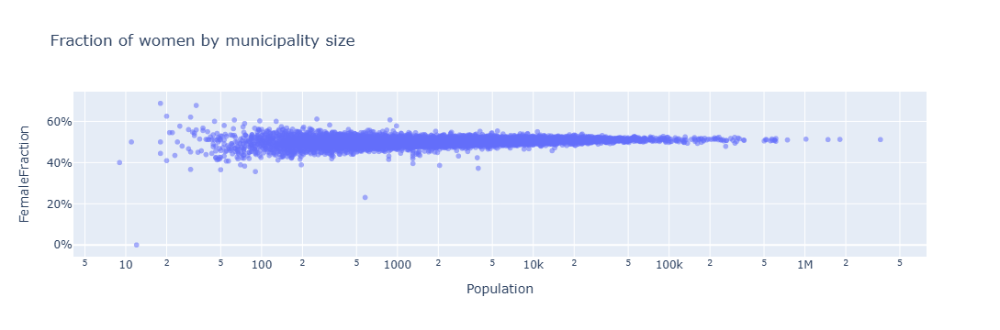

In [6]:
gender_counts = census[
    (census["MunicipalityID"] != 0) &
    (census["Age"] == "Overall") &
    (census["Marital status"] == "Overall") &
    (census["Gender"].isin(["Female", "Male"]))
].pivot(index="MunicipalityID", columns="Gender", values="Count").reset_index()

female_fraction = municipality_size.merge(gender_counts, on="MunicipalityID")
female_fraction["FemaleFraction"] = (
    female_fraction["Female"] /
    (female_fraction["Female"] + female_fraction["Male"])
)

fig = px.scatter(
    female_fraction,
    x="Population",
    y="FemaleFraction",
    log_x=True,
    hover_name="Municipality",
    hover_data={
        "MunicipalityID": True,
        "Population": ":,",
        "Female": ":,",
        "Male": ":,",
        "FemaleFraction": ":.2%"
    },
    opacity=0.55,
    title="Fraction of women by municipality size"
)
fig.update_yaxes(tickformat=".0%")
fig.show()

In [7]:
print("Median female fraction:", f'{female_fraction["FemaleFraction"].median():.2%}')
print("Correlation with log10(population):",
      round(female_fraction["FemaleFraction"].corr(np.log10(female_fraction["Population"])), 3))

print("\nLowest female fractions among municipalities with at least 1,000 residents:")
display(
    female_fraction[female_fraction["Population"] >= 1_000]
    .nsmallest(5, "FemaleFraction")
    [["Municipality", "Population", "FemaleFraction"]]
)

print("Highest female fractions among municipalities with at least 1,000 residents:")
display(
    female_fraction[female_fraction["Population"] >= 1_000]
    .nlargest(5, "FemaleFraction")
    [["Municipality", "Population", "FemaleFraction"]]
)

Median female fraction: 50.30%
Correlation with log10(population): 0.229

Lowest female fractions among municipalities with at least 1,000 residents:


,Municipality,Population,FemaleFraction
9883,Sengenthal,3937,0.372430
7811,"Osterheide, gemfr. Bezirk",2042,0.386119
4890,Untermaßfeld,1300,0.395385
1427,Bliesdorf,1298,0.419429
3169,"Kaisheim, M",3872,0.423633


Highest female fractions among municipalities with at least 1,000 residents:


,Municipality,Population,FemaleFraction
8587,Rottach-Egern,5448,0.553211
638,Waldbreitbach,1913,0.551958
10052,"Graal-Müritz, Ostseeheilbad",4054,0.551716
2332,"Prien a.Chiemsee, M",10736,0.549739
8929,Bad Eilsen,2500,0.547200


The median municipality is 50.3% female. The scatter narrows strongly as municipality size increases, because demographic differences have a much larger effect on proportions in very small municipalities. There is only a weak positive association with size (r ≈ 0.23 against log population). The interactive hover is useful for inspecting outliers: for example, among municipalities above 1,000 residents, Sengenthal is unusually low at about 37.2% women, while Rottach-Egern is unusually high at about 55.3%.

## 2.4 Fraction of women by age bracket

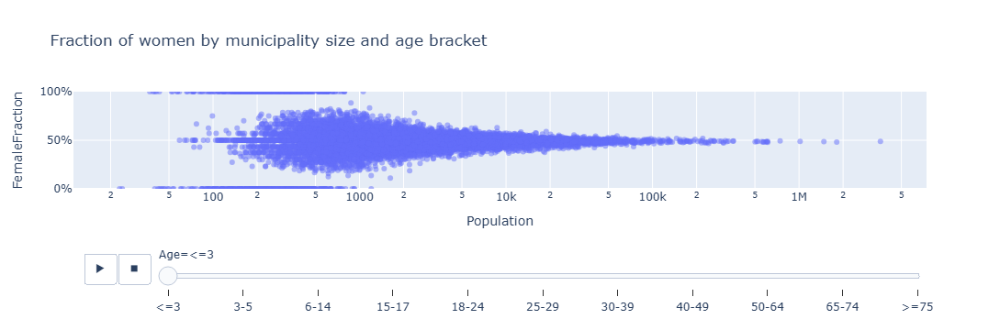

In [8]:
sex_by_age = census[
    (census["MunicipalityID"] != 0) &
    (census["Age"] != "Overall") &
    (census["Marital status"] == "Overall") &
    (census["Gender"].isin(["Female", "Male"]))
].pivot(index=["MunicipalityID", "Age"], columns="Gender", values="Count").reset_index()

female_by_age = sex_by_age.dropna(subset=["Female", "Male"]).copy()
female_by_age["SexTotal"] = female_by_age["Female"] + female_by_age["Male"]
female_by_age = female_by_age[female_by_age["SexTotal"] > 0].copy()
female_by_age["FemaleFraction"] = female_by_age["Female"] / female_by_age["SexTotal"]

female_by_age = female_by_age.merge(
    municipality_size[["MunicipalityID", "Municipality", "Population"]],
    on="MunicipalityID"
)
female_by_age["Age"] = pd.Categorical(
    female_by_age["Age"], categories=age_order, ordered=True
)
female_by_age = female_by_age.sort_values("Age")

fig = px.scatter(
    female_by_age,
    x="Population",
    y="FemaleFraction",
    animation_frame="Age",
    log_x=True,
    range_y=[0, 1],
    hover_name="Municipality",
    hover_data={
        "MunicipalityID": True,
        "SexTotal": ":,",
        "FemaleFraction": ":.2%"
    },
    opacity=0.5,
    category_orders={"Age": age_order},
    title="Fraction of women by municipality size and age bracket"
)
fig.update_yaxes(tickformat=".0%")
fig.show()

In [9]:
national_gender_age = census[
    (census["MunicipalityID"] == 0) &
    (census["Age"] != "Overall") &
    (census["Marital status"] == "Overall") &
    (census["Gender"].isin(["Female", "Male"]))
].pivot(index="Age", columns="Gender", values="Count").reset_index()

national_gender_age["FemaleFraction"] = (
    national_gender_age["Female"] /
    (national_gender_age["Female"] + national_gender_age["Male"])
)
national_gender_age["Age"] = pd.Categorical(
    national_gender_age["Age"], categories=age_order, ordered=True
)
national_gender_age = national_gender_age.sort_values("Age")

display(
    national_gender_age[["Age", "FemaleFraction"]]
    .style.format({"FemaleFraction": "{:.1%}"})
)

all_municipality_age_cells = 10786 * 11
print("Municipality-age cells not plotted because the sex-specific fraction is undefined:",
      all_municipality_age_cells - len(female_by_age))

Gender,Age,FemaleFraction
9,<=3,48.7%
3,3-5,48.8%
7,6-14,48.7%
0,15-17,48.5%
1,18-24,48.4%
2,25-29,48.3%
4,30-39,49.1%
5,40-49,49.9%
6,50-64,50.2%
8,65-74,52.7%


Municipality-age cells not plotted because the sex-specific fraction is undefined: 1149


The age-specific picture is systematic. Nationally, women make up roughly 48–49% of the population in the younger brackets, the ratio approaches parity around ages 40–64, and women become the majority at older ages: about 52.7% at 65–74 and 59.5% at 75+. Small municipalities again show the widest scatter. A small number of municipality-age cells cannot produce a sex fraction because one sex-specific row is unavailable or the female+male denominator is zero; those undefined cells are omitted rather than filled with invented values.

## 2.5 Marital status over age brackets and gender
For this nationwide comparison I use MunicipalityID = 0 directly. Because the preprocessing combines marriage/legal-partnership categories into the same labels, identical keys can occur in the national rows; grouping and summing those rows gives the intended combined category.

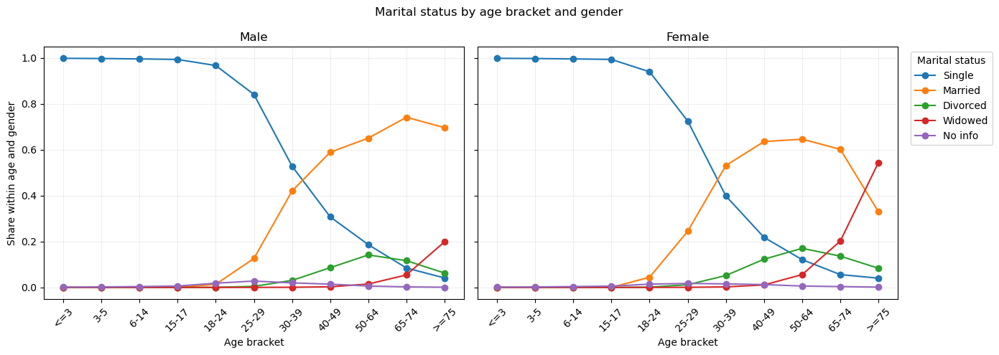

In [10]:
national_marital = census[
    (census["MunicipalityID"] == 0) &
    (census["Age"] != "Overall") &
    (census["Gender"].isin(["Male", "Female"]))
].groupby(["Age", "Gender", "Marital status"], as_index=False)["Count"].sum()

marital_total = national_marital[
    national_marital["Marital status"] == "Overall"
][["Age", "Gender", "Count"]].rename(columns={"Count": "Total"})

marital_share = national_marital[
    national_marital["Marital status"] != "Overall"
].merge(marital_total, on=["Age", "Gender"])

marital_share["Share"] = marital_share["Count"] / marital_share["Total"]
marital_share["Age"] = pd.Categorical(marital_share["Age"], categories=age_order, ordered=True)
marital_share = marital_share.sort_values("Age")

statuses = ["Single", "Married", "Divorced", "Widowed", "No info"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, gender in zip(axes, ["Male", "Female"]):
    part = marital_share[marital_share["Gender"] == gender]
    for status in statuses:
        line = part[part["Marital status"] == status]
        ax.plot(line["Age"].astype(str), line["Share"], marker="o", label=status)
    ax.set_title(gender)
    ax.set_xlabel("Age bracket")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Share within age and gender")
axes[1].legend(title="Marital status", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("Marital status by age bracket and gender")
plt.tight_layout()
plt.show()

In [11]:
selected = marital_share[
    marital_share["Age"].isin(["18-24", "30-39", "50-64", ">=75"])
].pivot_table(
    index=["Gender", "Age"],
    columns="Marital status",
    values="Share",
    observed=False
)
display(selected[statuses].style.format("{:.1%}"))

Almost everyone below 18 is single. In ages 18–24, about 96.7% of men and 94.0% of women are single. By ages 30–39, marriage is already more common among women (53.2% married) than men (42.0%), while 52.9% of men and 39.9% of women are still single. At 50–64, roughly two thirds of both sexes are married and divorce is also common. The largest gender difference appears at old ages: among people 75+, about 54.5% of women are widowed compared with 19.9% of men, while 69.6% of men but only 33.0% of women are married.

## 2.6 Cumulative age distributions and PCA
Each municipality is represented by its 11 age-bracket shares. I normalize the 11 age counts by their own sum and then take the cumulative sum, so the last coordinate is exactly 1 as requested.

In [12]:
age_counts = census[
    (census["MunicipalityID"] != 0) &
    (census["Age"] != "Overall") &
    (census["Marital status"] == "Overall") &
    (census["Gender"] == "Overall")
][["MunicipalityID", "Age", "Count"]]

age_matrix = (
    age_counts
    .pivot(index="MunicipalityID", columns="Age", values="Count")
    .reindex(columns=age_order)
)

age_relative = age_matrix.div(age_matrix.sum(axis=1), axis=0)
age_cumulative = age_relative.cumsum(axis=1)

print("Matrix shape:", age_cumulative.shape)
print("Largest deviation of final cumulative entry from 1:",
      np.abs(age_cumulative.iloc[:, -1] - 1).max())

pca = PCA().fit(age_cumulative)
scores = pca.transform(age_cumulative)
explained = pca.explained_variance_ratio_
cumulative_explained = np.cumsum(explained)

pca_table = pd.DataFrame({
    "PC": np.arange(1, 12),
    "Explained variance": explained,
    "Cumulative explained variance": cumulative_explained
})
display(pca_table.style.format({
    "Explained variance": "{:.2%}",
    "Cumulative explained variance": "{:.2%}"
}))

Matrix shape: (10786, 11)
Largest deviation of final cumulative entry from 1: 2.220446049250313e-16


,PC,Explained variance,Cumulative explained variance
0,1,82.82%,82.82%
1,2,6.90%,89.72%
2,3,4.58%,94.29%
3,4,2.07%,96.36%
4,5,1.28%,97.64%
5,6,1.19%,98.82%
6,7,0.55%,99.38%
7,8,0.29%,99.66%
8,9,0.20%,99.86%
9,10,0.14%,100.00%


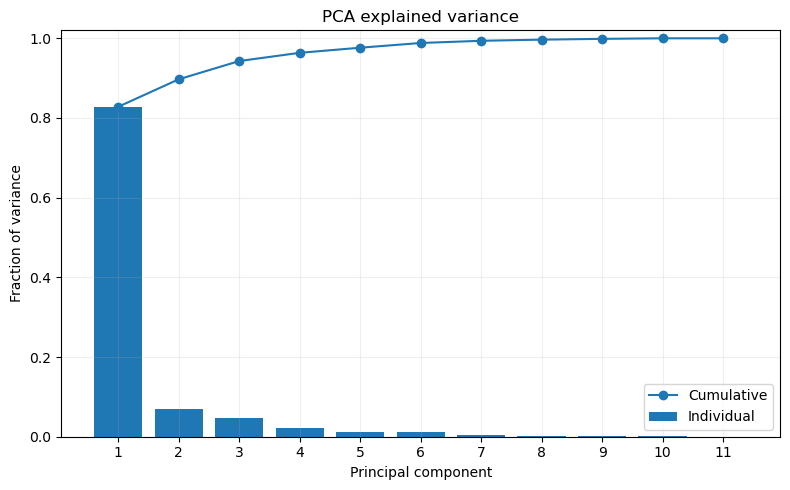

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(pca_table["PC"], pca_table["Explained variance"], label="Individual")
ax.plot(pca_table["PC"], pca_table["Cumulative explained variance"], marker="o", label="Cumulative")
ax.set_xticks(range(1, 12))
ax.set_ylim(0, 1.02)
ax.set_xlabel("Principal component")
ax.set_ylabel("Fraction of variance")
ax.set_title("PCA explained variance")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

The point cloud is strongly low-dimensional. PC1 alone explains 82.8% of the variance; the first 2 PCs explain 89.7%, the first 3 explain 94.3%, and the first 4 explain 96.4%. Therefore a practical effective dimension is about 3–4, depending on the desired accuracy. The 11th component has zero variance because the final cumulative coordinate is always exactly 1.

## 2.7 Average age distribution and the first three PCA eigenvectors
The PCA was performed on cumulative distributions. To interpret the eigenvectors in terms of the original age shares, I invert the cumulative-sum operation using consecutive differences.

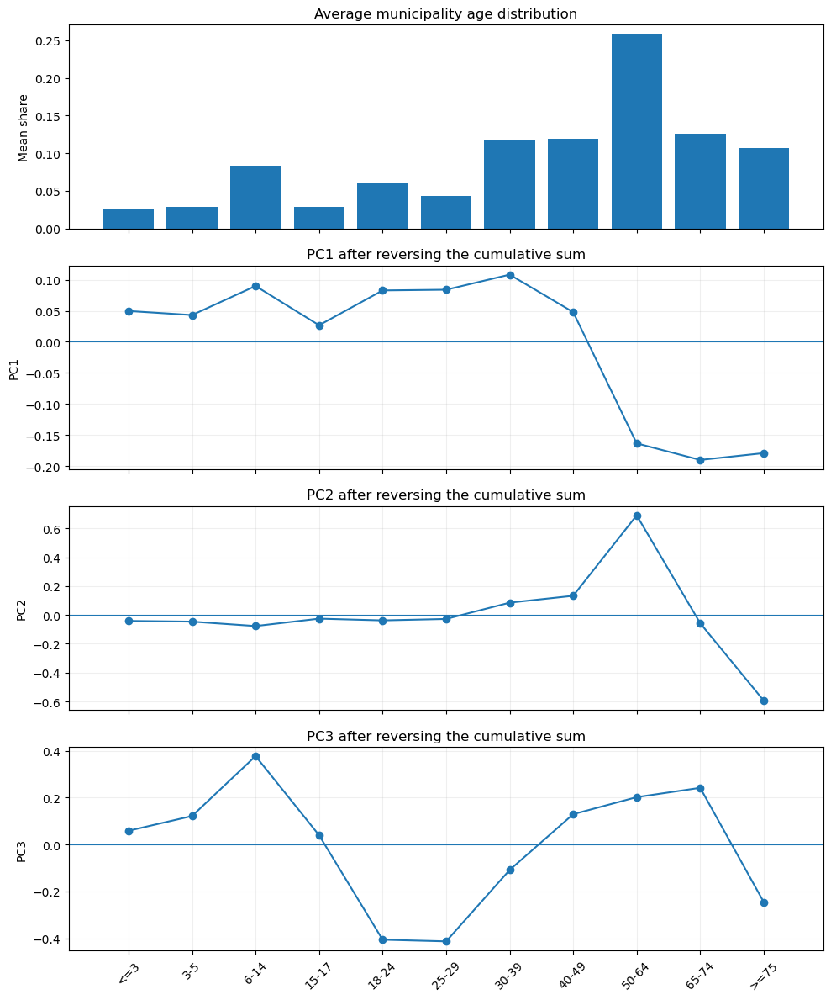

In [14]:
mean_cdf = age_cumulative.mean(axis=0).to_numpy()
mean_distribution = np.diff(np.r_[0, mean_cdf])

inverse_components = np.vstack([
    np.diff(np.r_[0, pca.components_[i]])
    for i in range(3)
])

fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True)

axes[0].bar(age_order, mean_distribution)
axes[0].set_ylabel("Mean share")
axes[0].set_title("Average municipality age distribution")

for i in range(3):
    axes[i + 1].plot(age_order, inverse_components[i], marker="o")
    axes[i + 1].axhline(0, linewidth=0.8)
    axes[i + 1].set_ylabel(f"PC{i+1}")
    axes[i + 1].set_title(f"PC{i+1} after reversing the cumulative sum")
    axes[i + 1].grid(alpha=0.2)

axes[-1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [15]:
for i in range(3):
    values = inverse_components[i]
    strongest_positive = np.argsort(values)[-4:][::-1]
    strongest_negative = np.argsort(values)[:4]
    print(f"PC{i+1}")
    print("  positive:", ", ".join(age_order[j] for j in strongest_positive))
    print("  negative:", ", ".join(age_order[j] for j in strongest_negative))

PC1
  positive: 30-39, 6-14, 25-29, 18-24
  negative: 65-74, >=75, 50-64, 15-17
PC2
  positive: 50-64, 40-49, 30-39, 15-17
  negative: >=75, 6-14, 65-74, 3-5
PC3
  positive: 6-14, 65-74, 50-64, 40-49
  negative: 25-29, 18-24, >=75, 30-39


With the sign convention returned by sklearn (the sign itself is arbitrary):
- PC1 is primarily a young-versus-old contrast. Positive PC1 adds weight to children and young/middle adults (especially 6–14 and 18–39) and removes weight from ages 50+, especially 65–74 and 75+.
- PC2 mainly contrasts 50–64-year-olds with the very old: its strongest positive loading is 50–64 and its strongest negative loading is 75+.
- PC3 separates a pattern with more children and ages 50–74 from one with more young adults (18–29) and, to a lesser extent, 75+.
Thus the first components describe broad demographic shifts rather than isolated changes in a single age bracket.

## 2.8 PCA coordinates versus municipality size and location

In [16]:
score_df = pd.DataFrame(
    scores[:, :3],
    index=age_cumulative.index,
    columns=["PC1", "PC2", "PC3"]
).reset_index()

pca_data = (
    score_df
    .merge(municipality_size, on="MunicipalityID")
    .merge(locations[["MunicipalityID", "lon", "lat"]], on="MunicipalityID")
)
pca_data["logPopulation"] = np.log10(pca_data["Population"])

correlations = pca_data[["PC1", "PC2", "PC3", "logPopulation", "lon", "lat"]].corr()
display(correlations.loc[["PC1", "PC2", "PC3"], ["logPopulation", "lon", "lat"]].round(3))

,logPopulation,lon,lat
PC1,0.211,-0.218,-0.278
PC2,-0.351,0.032,0.122
PC3,-0.260,0.275,0.224


### Chart 1 — PCA plane and municipality size

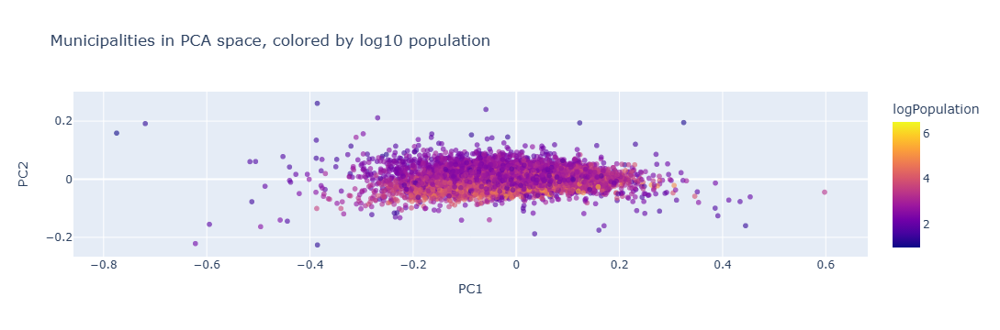

In [17]:
fig = px.scatter(
    pca_data,
    x="PC1",
    y="PC2",
    color="logPopulation",
    hover_name="Municipality",
    hover_data={"Population": ":,", "PC1": ":.3f", "PC2": ":.3f", "PC3": ":.3f"},
    opacity=0.6,
    title="Municipalities in PCA space, colored by log10 population"
)
fig.show()

### Chart 2 — PCA coordinates versus population

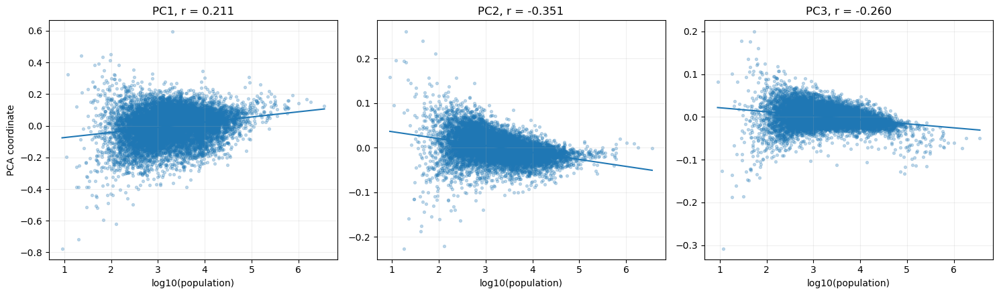

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, pc in zip(axes, ["PC1", "PC2", "PC3"]):
    x = pca_data["logPopulation"].to_numpy()
    y = pca_data[pc].to_numpy()
    ax.scatter(x, y, s=8, alpha=0.25)
    slope, intercept = np.polyfit(x, y, 1)
    xx = np.linspace(x.min(), x.max(), 100)
    ax.plot(xx, slope * xx + intercept)
    r = np.corrcoef(x, y)[0, 1]
    ax.set_title(f"{pc}, r = {r:.3f}")
    ax.set_xlabel("log10(population)")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("PCA coordinate")
plt.tight_layout()
plt.show()

### Chart 3 — Geographic pattern of PC1

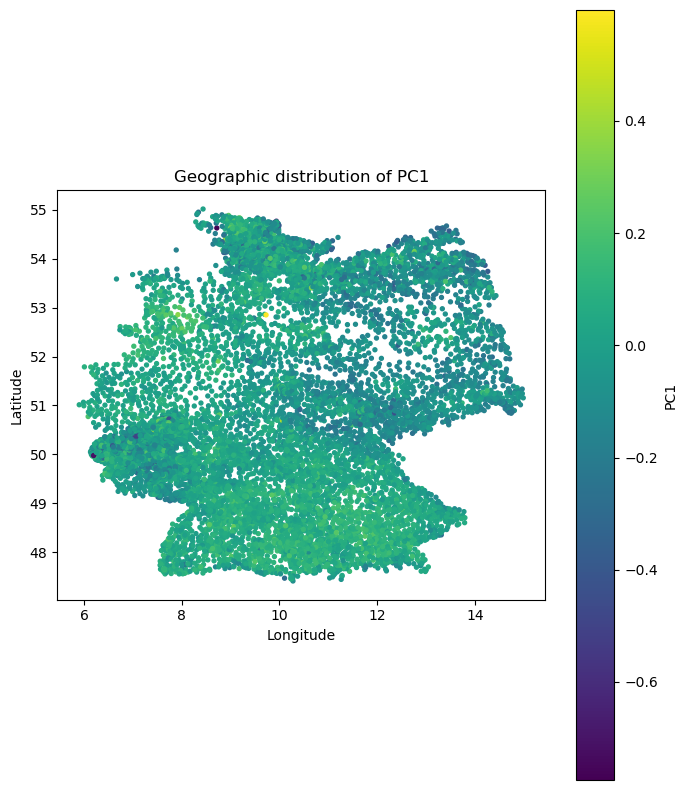

In [19]:
fig, ax = plt.subplots(figsize=(7, 8))
sc = ax.scatter(pca_data["lon"], pca_data["lat"], c=pca_data["PC1"], s=8)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Geographic distribution of PC1")
ax.set_aspect("equal", adjustable="box")
plt.colorbar(sc, ax=ax, label="PC1")
plt.tight_layout()
plt.show()

### Chart 4 — Geographic patterns of PC2 and PC3

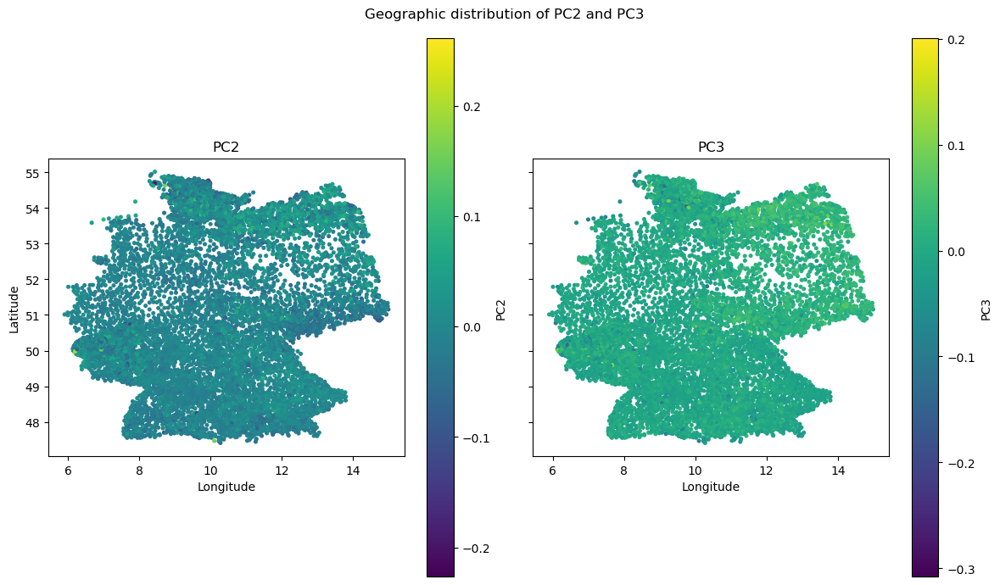

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 7), sharex=True, sharey=True)
for ax, pc in zip(axes, ["PC2", "PC3"]):
    sc = ax.scatter(pca_data["lon"], pca_data["lat"], c=pca_data[pc], s=7)
    ax.set_title(pc)
    ax.set_xlabel("Longitude")
    ax.set_aspect("equal", adjustable="box")
    plt.colorbar(sc, ax=ax, label=pc)
axes[0].set_ylabel("Latitude")
fig.suptitle("Geographic distribution of PC2 and PC3")
plt.tight_layout()
plt.show()

In [21]:
print("Linear R² using longitude + latitude:")
for pc in ["PC1", "PC2", "PC3"]:
    model = LinearRegression().fit(pca_data[["lon", "lat"]], pca_data[pc])
    r2 = model.score(pca_data[["lon", "lat"]], pca_data[pc])
    print(pc, f"{r2:.3f}")

Linear R² using longitude + latitude:
PC1 0.106
PC2 0.015
PC3 0.107


The dependencies are real but not deterministic.
- Municipality size has a modest association with all three coordinates: r = +0.211 for PC1, -0.351 for PC2, and -0.260 for PC3 against log population. The strongest size effect is therefore on PC2.
- PC1 has noticeable geographic gradients (r = -0.218 with longitude and -0.278 with latitude). A linear model using longitude and latitude explains about 10.6% of PC1 variance.
- PC2 is much less geographic (r = 0.032 with longitude and 0.122 with latitude; geographic linear $R^2 \approx  1.5%$), so its pattern is more closely related to municipality size than simple location.
- PC3 shows another geographic gradient (r = +0.275 with longitude and +0.224 with latitude), with longitude and latitude together explaining about 10.7% of its variance.
Overall, municipality size and geography both contribute to demographic age structure, but neither explains the PCA coordinates on its own. PC1 and PC3 show the clearest spatial structure, while PC2 shows the clearest relationship with municipality size.

The census data show a strongly skewed municipal population structure: many German municipalities are small, while a large share of residents is concentrated in larger municipalities. Gender composition is close to balanced overall but becomes clearly female-dominated at old ages. Marital status changes strongly with age and differs between men and women, especially at 75+. Finally, municipality age profiles are highly compressible: three principal components already capture about 94% of their variation, and these components show modest but visible relationships with both municipality size and geographic location.